<a href="https://colab.research.google.com/github/OrochinhodoTI/ia-ciberseguran-a-teste-modificada-da-aula4.1/blob/main/aulas4_metricas_validacao_phishing_alunos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IA para Cibersegurança — Aulas 4 e 5
## Métricas, validação e um classificador de phishing de ponta a ponta

**Dupla:** `Guilherme`  ·  `Monteiro`

> Rodem as células na ordem.

Nesta aula veremos:
- **Métricas e validação:** como saber se um modelo é *bom de verdade* em segurança (por que acurácia engana, precisão × recall, ROC/PR, limiar de decisão, validação sem vazamento).


Usamos uma base **real**: a **PhiUSIIL Phishing URL Dataset** (UCI, ~236 mil URLs), baixada direto em Python. Se o download falhar, o notebook cai automaticamente numa base real (PhiUSIIL) equivalente, para nunca travar a aula.

### 1. Bibliotecas e configuração

In [1]:
!pip install -q ucimlrepo

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report,
                             roc_auc_score, average_precision_score,
                             roc_curve, precision_recall_curve)

sns.set_theme(style='whitegrid')
RANDOM_SEED = 33
np.random.seed(RANDOM_SEED)

### 2. A base de phishing (PhiUSIIL)
Cada linha é um site/URL descrito por dezenas de features extraídas da URL e do código-fonte da página. O rótulo original vem **invertido** (1 = legítimo, -1 = phishing); nós convertemos para `is_phishing` (1 = phishing).

In [2]:
# Base real: UCI Phishing Websites (Mohammad et al., id=327)
# Rótulo original: coluna 'Result' com 1 = LEGÍTIMO e -1 = PHISHING.
RANDOM_SEED = 33
import numpy as np, pandas as pd
np.random.seed(RANDOM_SEED)

def carregar_uci_phishing():
    from ucimlrepo import fetch_ucirepo
    ds = fetch_ucirepo(id=327)
    X = ds.data.features.copy()
    y = ds.data.targets.copy()
    df = pd.concat([X, y], axis=1)
    df.columns = [str(c).strip() for c in df.columns]

    # a coluna de rótulo costuma se chamar 'Result' (ou 'result')
    col_rotulo = [c for c in df.columns if c.lower() in ('result', 'class', 'label')][0]
    # -1 (phishing) -> 1 ; 1 (legítimo) -> 0
    df['is_phishing'] = (df[col_rotulo] == -1).astype(int)
    df = df.drop(columns=[col_rotulo])

    # aqui todas as features já são numéricas; mantemos só numéricas por segurança
    num = df.select_dtypes(include=[np.number]).columns.tolist()
    df = df[num]
    return df.sample(frac=1, random_state=RANDOM_SEED).reset_index(drop=True)

def gerar_base_sintetica():
    rng = np.random.default_rng(RANDOM_SEED)
    nl, npish = 8000, 2500
    legit = pd.DataFrame({
        'url_length': np.clip(rng.normal(52,24,nl),5,None), 'num_dots': np.clip(rng.normal(2.8,1.4,nl),0,None),
        'num_subdominios': np.clip(rng.normal(1.4,1.0,nl),0,None), 'tem_ip_na_url': (rng.random(nl)<0.06).astype(int),
        'tem_arroba': (rng.random(nl)<0.08).astype(int), 'tem_https': (rng.random(nl)<0.78).astype(int),
        'idade_dominio_dias': np.clip(rng.normal(1100,850,nl),1,None), 'num_chars_especiais': np.clip(rng.normal(4,3,nl),0,None),
        'palavras_suspeitas': rng.poisson(0.6,nl), 'num_redirecionamentos': rng.poisson(0.7,nl)}); legit['is_phishing']=0
    phish = pd.DataFrame({
        'url_length': np.clip(rng.normal(66,28,npish),5,None), 'num_dots': np.clip(rng.normal(3.7,1.7,npish),0,None),
        'num_subdominios': np.clip(rng.normal(2.1,1.3,npish),0,None), 'tem_ip_na_url': (rng.random(npish)<0.20).astype(int),
        'tem_arroba': (rng.random(npish)<0.22).astype(int), 'tem_https': (rng.random(npish)<0.62).astype(int),
        'idade_dominio_dias': np.clip(rng.normal(380,400,npish),1,None), 'num_chars_especiais': np.clip(rng.normal(6.5,4.5,npish),0,None),
        'palavras_suspeitas': rng.poisson(1.5,npish), 'num_redirecionamentos': rng.poisson(1.3,npish)}); phish['is_phishing']=1
    return pd.concat([legit,phish],ignore_index=True).sample(frac=1,random_state=RANDOM_SEED).reset_index(drop=True)

try:
    df = carregar_uci_phishing()
    print('Base: UCI Phishing Websites (real).')
except Exception as e:
    print('Falha ao baixar a UCI (', type(e).__name__, ') -> usando base sintética.')
    df = gerar_base_sintetica()

Base: UCI Phishing Websites (real).


### 3. EDA rápida
O primeiro reflexo: **quão desbalanceada** é a base?

/tmp/ipykernel_10912/852752903.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[1].set_xticklabels(['Legítimo', 'Phishing']); ax[1].set_title(f'{feat} por classe')


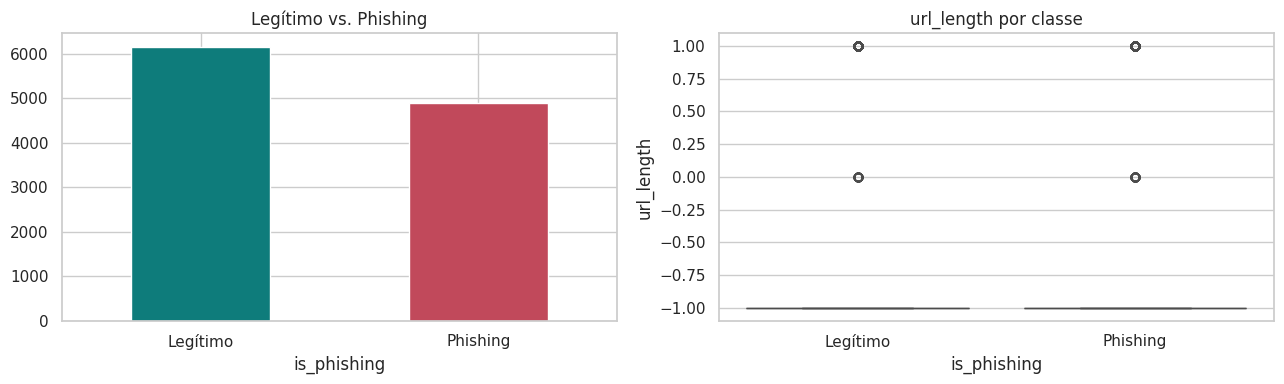

Feature comparada: url_length


In [3]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
df['is_phishing'].map({0:'Legítimo', 1:'Phishing'}).value_counts().plot(
    kind='bar', ax=ax[0], color=['#0E7C7B', '#C1495B'])
ax[0].set_title('Legítimo vs. Phishing'); ax[0].tick_params(axis='x', rotation=0)

# escolhe uma feature de tamanho da URL que exista (real ou sintética)
cand = [c for c in ['URLLength', 'url_length', 'DomainLength'] if c in df.columns]
feat = cand[0] if cand else df.drop(columns='is_phishing').columns[0]
sns.boxplot(data=df, x='is_phishing', y=feat, ax=ax[1])
ax[1].set_xticklabels(['Legítimo', 'Phishing']); ax[1].set_title(f'{feat} por classe')
plt.tight_layout(); plt.show()
print('Feature comparada:', feat)

**O que observar:** veja se as classes estão desbalanceadas e se a feature escolhida já separa visualmente phishing de legítimo. Guardem a proporção — é a chave da próxima célula.

### 4. Por que acurácia engana
Antes de treinar qualquer modelo: e se a gente **chutasse “legítimo” para tudo**?

In [4]:
baseline_acc = (df['is_phishing'] == 0).mean()
print(f'Classe majoritária = legítimo ({baseline_acc:.1%} da base).')
print(f'Um "modelo" que sempre diz LEGÍTIMO teria acurácia de {baseline_acc:.1%}...')
print('...e não detectaria UM ÚNICO phishing. Por isso acurácia sozinha não serve.')

Classe majoritária = legítimo (55.7% da base).
Um "modelo" que sempre diz LEGÍTIMO teria acurácia de 55.7%...
...e não detectaria UM ÚNICO phishing. Por isso acurácia sozinha não serve.


### 5. Preparação e split (sem vazamento)
Separamos treino e teste **antes** de qualquer ajuste. Essa ordem evita **data leakage**: o modelo nunca pode “espiar” o teste. Usamos `stratify` para manter a proporção de phishing nos dois lados.

In [5]:
X = df.drop(columns='is_phishing')
y = df['is_phishing']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=RANDOM_SEED)

print('Treino:', X_train.shape, '| Teste:', X_test.shape)
print('Phishing — treino: {:.1%} | teste: {:.1%}'.format(y_train.mean(), y_test.mean()))

Treino: (7738, 30) | Teste: (3317, 30)
Phishing — treino: 44.3% | teste: 44.3%


### 6. Treinar um modelo
Mudei o Random Forest por Regressão Logística para testa modelo linear muito mais simples e rápido, que e a Regressão Logística.

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

# Em vez de escolher apenas 5 manualmente, capturamos TODAS as colunas usadas no X_train
features_disponiveis = X_train.columns.tolist()

X_train_reduzido = X_train[features_disponiveis]
X_test_reduzido = X_test[features_disponiveis]

# Aplicar o escalonamento para todas as variáveis
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_reduzido)
X_test_scaled = scaler.transform(X_test_reduzido)

# Treinar a Regressão Logística com o conjunto completo
lr = LogisticRegression(class_weight='balanced', random_state=RANDOM_SEED, max_iter=2000)
lr.fit(X_train_scaled, y_train)

# Atualizar as previsões
y_pred = lr.predict(X_test_scaled)
y_proba = lr.predict_proba(X_test_scaled)[:, 1]

print(f'Modelo de Regressão Logística treinado usando o máximo de {len(features_disponiveis)} features.')

Modelo de Regressão Logística treinado usando o máximo de 30 features.


### 7. Matriz de confusão
Os quatro números que explicam tudo. Em phishing:
- **Falso positivo (FP):** site legítimo marcado como phishing → usuário bloqueado à toa.
- **Falso negativo (FN):** phishing que passou como legítimo → usuário exposto ao golpe.

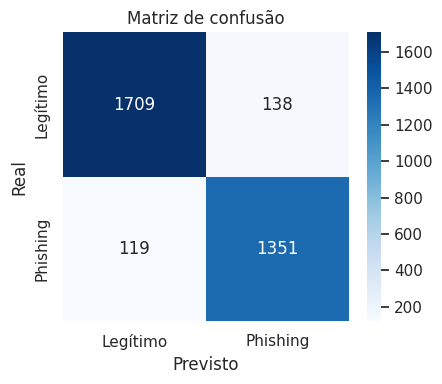

Verdadeiros phishing detectados (TP): 1351
Phishing que passaram   (FN): 119   <- os mais perigosos
Alarmes falsos          (FP): 138


In [7]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(4.6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Legítimo', 'Phishing'], yticklabels=['Legítimo', 'Phishing'])
plt.xlabel('Previsto'); plt.ylabel('Real'); plt.title('Matriz de confusão'); plt.tight_layout(); plt.show()

tn, fp, fn, tp = cm.ravel()
print(f'Verdadeiros phishing detectados (TP): {tp}')
print(f'Phishing que passaram   (FN): {fn}   <- os mais perigosos')
print(f'Alarmes falsos          (FP): {fp}')

### 8. Precisão, recall e F1
- **Precisão:** dos que o modelo *chamou de phishing*, quantos eram mesmo? (evita alarme falso)
- **Recall:** dos phishing *que existiam*, quantos o modelo pegou? (evita deixar passar)
- **F1:** equilíbrio entre os dois.

In [8]:
# Cálculo direto dos phishings identificados
tp = ((y_pred == 1) & (y_test == 1)).sum()  # Phishings reais detectados (Verdadeiros Positivos)
total_phish_reais = (y_test == 1).sum()    # Total de phishings existentes no teste
total_alertas = (y_pred == 1).sum()        # Total sinalizado como phishing pelo modelo (TP + FP)

print(classification_report(y_test, y_pred, target_names=['Legítimo', 'Phishing']))
print(f'Phishing detectados (TP) : {tp} de {total_phish_reais} reais (Alertas emitidos: {total_alertas})')
print(f'Acurácia                 : {accuracy_score(y_test, y_pred):.3f}   (baseline "tudo legítimo": {baseline_acc:.3f})')
print(f'Precisão                 : {precision_score(y_test, y_pred):.3f}')
print(f'Recall                   : {recall_score(y_test, y_pred):.3f}   <- o modelo deixou passar parte dos phishing')
print(f'F1                       : {f1_score(y_test, y_pred):.3f}')

              precision    recall  f1-score   support

    Legítimo       0.93      0.93      0.93      1847
    Phishing       0.91      0.92      0.91      1470

    accuracy                           0.92      3317
   macro avg       0.92      0.92      0.92      3317
weighted avg       0.92      0.92      0.92      3317

Phishing detectados (TP) : 1351 de 1470 reais (Alertas emitidos: 1489)
Acurácia                 : 0.923   (baseline "tudo legítimo": 0.557)
Precisão                 : 0.907
Recall                   : 0.919   <- o modelo deixou passar parte dos phishing
F1                       : 0.913


**O que observar:** a acurácia parece boa, mas o **recall** revela que o modelo deixa passar uma fatia dos phishing. É esse tipo de erro que queremos reduzir, o que nos leva ao **limiar**.

### 9. ROC-AUC e PR-AUC
Métricas que olham o modelo em **todos os limiares** de uma vez.
- **ROC-AUC:** capacidade geral de separar as classes.
- **PR-AUC:** foca na classe rara (phishing).

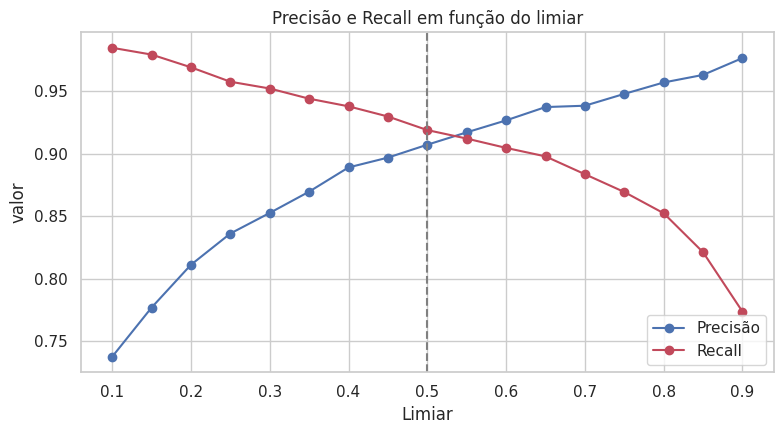

limiar 0.3:  precisão 0.85  |  recall 0.95
limiar 0.5:  precisão 0.91  |  recall 0.92
limiar 0.7:  precisão 0.94  |  recall 0.88


In [9]:
limiares = np.arange(0.1, 0.91, 0.05)
precisoes = [precision_score(y_test, (y_proba >= t).astype(int), zero_division=0) for t in limiares]
recalls   = [recall_score(y_test, (y_proba >= t).astype(int)) for t in limiares]

plt.figure(figsize=(8, 4.5))
plt.plot(limiares, precisoes, 'o-', label='Precisão')
plt.plot(limiares, recalls,   'o-', label='Recall', color='#C1495B')
plt.axvline(0.5, ls='--', color='gray'); plt.xlabel('Limiar'); plt.ylabel('valor')
plt.title('Precisão e Recall em função do limiar'); plt.legend(); plt.tight_layout(); plt.show()

for t in [0.3, 0.5, 0.7]:
    p = (y_proba >= t).astype(int)
    print(f'limiar {t}:  precisão {precision_score(y_test,p,zero_division=0):.2f}  |  recall {recall_score(y_test,p):.2f}')

### 10. O limiar de decisão e o custo dos erros
Por padrão o modelo chama de phishing quando a probabilidade ≥ 0,5. Mas **nós escolhemos esse corte**. Baixá-lo pega mais phishing (recall ↑) ao custo de mais alarmes falsos (precisão ↓).

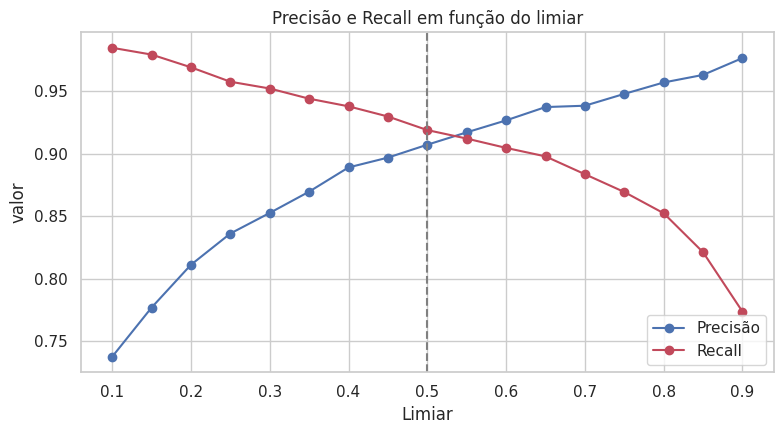

limiar 0.3:  precisão 0.85  |  recall 0.95
limiar 0.5:  precisão 0.91  |  recall 0.92
limiar 0.7:  precisão 0.94  |  recall 0.88


In [10]:
limiares = np.arange(0.1, 0.91, 0.05)
precisoes = [precision_score(y_test, (y_proba >= t).astype(int), zero_division=0) for t in limiares]
recalls   = [recall_score(y_test, (y_proba >= t).astype(int)) for t in limiares]

plt.figure(figsize=(8, 4.5))
plt.plot(limiares, precisoes, 'o-', label='Precisão')
plt.plot(limiares, recalls,   'o-', label='Recall', color='#C1495B')
plt.axvline(0.5, ls='--', color='gray'); plt.xlabel('Limiar'); plt.ylabel('valor')
plt.title('Precisão e Recall em função do limiar'); plt.legend(); plt.tight_layout(); plt.show()

for t in [0.3, 0.5, 0.7]:
    p = (y_proba >= t).astype(int)
    print(f'limiar {t}:  precisão {precision_score(y_test,p,zero_division=0):.2f}  |  recall {recall_score(y_test,p):.2f}')

**Decisão de segurança:** se deixar passar phishing é o pior erro, escolhemos um limiar **mais baixo**, então, aceitamos mais alarmes falsos para não perder golpes. Não existe “limiar certo” universal: depende do custo de cada erro.

### 11. Validação mais robusta: validação cruzada
Um único split pode dar sorte (ou azar). A **validação cruzada** treina/testa em várias divisões e mostra o desempenho médio — mais confiável.

In [11]:
from sklearn.pipeline import make_pipeline

# Criamos um pipeline para garantir que o escalonamento seja aplicado em cada dobra da validação
pipeline = make_pipeline(StandardScaler(), lr)

# Como o modelo de Regressão Logística foi treinado apenas nas features reduzidas disponíveis:
X_reduzido = X[features_disponiveis]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)
scores = cross_val_score(pipeline, X_reduzido, y, cv=cv, scoring='f1')
print('F1 em cada divisão:', scores.round(3))
print(f'F1 médio: {scores.mean():.3f}  (±{scores.std():.3f})')

F1 em cada divisão: [0.918 0.922 0.911 0.919 0.919]
F1 médio: 0.918  (±0.004)


### Protocolo de avaliação (entregável da Parte A)
Fechamos aqui o **protocolo** que vamos usar no projeto:
- **Split:** treino/teste estratificado, feito **antes** de qualquer ajuste (sem vazamento).
- **Métrica principal:** recall de phishing (não deixar passar), acompanhada de precisão e F1.
- **Métrica global:** PR-AUC (mais honesta que acurácia no desbalanceamento).
- **Limiar:** escolhido conforme o custo dos erros, não fixo em 0,5.
- **Robustez:** validação cruzada de 5 divisões.

### 12. As features de phishing
Cada feature tenta capturar um “sinal” que costuma diferenciar um golpe de um site real.

In [12]:
resumo = df.groupby('is_phishing').mean().T
resumo.columns = ['Legítimo (média)', 'Phishing (média)']
resumo.round(2)

,Legítimo (média),Phishing (média)
having_ip_address,0.39,0.21
url_length,-0.59,-0.68
shortining_service,0.70,0.79
having_at_symbol,0.73,0.66
double_slash_redirecting,0.72,0.77
prefix_suffix,-0.52,-1.00
having_sub_domain,0.28,-0.21
sslfinal_state,0.83,-0.48
domain_registration_length,-0.53,-0.10
favicon,0.63,0.63


**O que observar:** URLs de phishing tendem a ser mais longas, com mais pontos/subdomínios, mais palavras suspeitas e domínios muito mais novos. São esses contrastes que o modelo aprende.

### 13. Quais features pesaram mais?

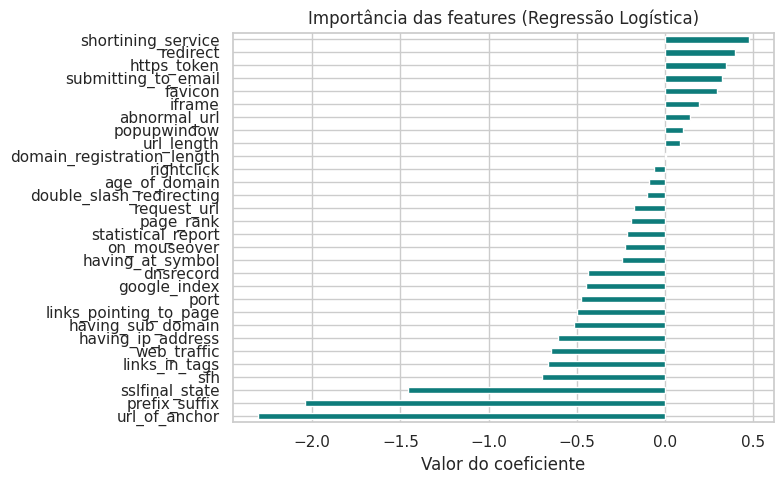

,0
shortining_service,0.480
redirect,0.396
https_token,0.348
submitting_to_email,0.323
favicon,0.294
iframe,0.196
abnormal_url,0.142
popupwindow,0.103
url_length,0.088
domain_registration_length,0.006


In [13]:
# Na Regressão Logística, avaliamos o peso de cada feature através dos coeficientes
importancias = pd.Series(lr.coef_[0], index=features_disponiveis).sort_values(ascending=False)

plt.figure(figsize=(8, 5))
importancias[::-1].plot(kind='barh', color='#0E7C7B')
plt.title('Importância das features (Regressão Logística)')
plt.xlabel('Valor do coeficiente')
plt.tight_layout()
plt.show()

display(importancias.round(3))

### 14. Aplicar o protocolo
Treinamos o modelo final e o avaliamos **exatamente segundo o protocolo** definido na Parte A: split estratificado, recall como métrica principal, limiar ajustado ao custo do erro.

In [14]:
# 1. Escolha o limiar desejado
LIMIAR = 0.2

# 2. Recalcule a previsão com base nas probabilidades salvas
y_final = (y_proba >= LIMIAR).astype(int)

# 3. Exiba as métricas atualizadas
print(
    f"=== Avaliação para Limiar {LIMIAR} (Total de Phishing Detectado:"
    f" {y_final.sum()}) ==="
)
print(
    classification_report(
        y_test, y_final, target_names=["Legítimo", "Phishing"]
    )
)

=== Avaliação para Limiar 0.2 (Total de Phishing Detectado: 1757) ===
              precision    recall  f1-score   support

    Legítimo       0.97      0.82      0.89      1847
    Phishing       0.81      0.97      0.88      1470

    accuracy                           0.89      3317
   macro avg       0.89      0.89      0.89      3317
weighted avg       0.90      0.89      0.89      3317



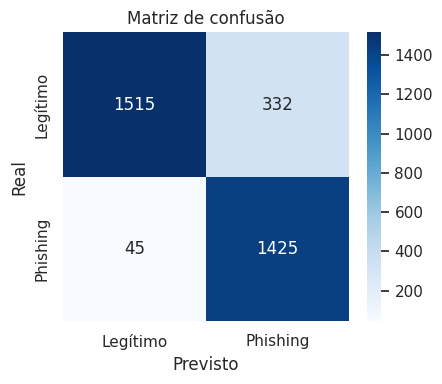

Verdadeiros phishing detectados (TP): 1425
Phishing que passaram   (FN): 45   <- os mais perigosos
Alarmes falsos          (FP): 332


In [15]:
cm = confusion_matrix(y_test, y_final)
plt.figure(figsize=(4.6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Legítimo', 'Phishing'], yticklabels=['Legítimo', 'Phishing'])
plt.xlabel('Previsto'); plt.ylabel('Real'); plt.title('Matriz de confusão'); plt.tight_layout(); plt.show()

tn, fp, fn, tp = cm.ravel()
print(f'Verdadeiros phishing detectados (TP): {tp}')
print(f'Phishing que passaram   (FN): {fn}   <- os mais perigosos')
print(f'Alarmes falsos          (FP): {fp}')

In [16]:
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix

def analisar_tradeoff_limiares(y_true, y_probs, limiar_padrao=0.50, limiar_novo=0.20):
    comparacao = []

    for t in [limiar_padrao, limiar_novo]:
        preds = (y_probs >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_true, preds).ravel()

        prec = precision_score(y_true, preds, zero_division=0)
        rec = recall_score(y_true, preds)
        acc = accuracy_score(y_true, preds)
        especificidade = tn / (tn + fp)

        comparacao.append({
            'Limiar': f'{t:.2f}',
            'Phishing Detectado (TP)': tp,
            'Phishing Perdido (FN)': fn,
            'Alarmes Falsos (FP)': fp,
            'Precisão': f'{prec:.2%}',
            'Recall': f'{rec:.2%}',
            'Especificidade': f'{especificidade:.2%}',
            'Acurácia Geral': f'{acc:.2%}'
        })

    df_resultado = pd.DataFrame(comparacao).set_index('Limiar')
    return df_resultado

# Executa a comparação usando as variáveis do seu notebook
df_tradeoff = analisar_tradeoff_limiares(y_test, y_proba, limiar_padrao=0.50, limiar_novo=0.20)
display(df_tradeoff)



,Phishing Detectado (TP),Phishing Perdido (FN),Alarmes Falsos (FP),Precisão,Recall,Especificidade,Acurácia Geral
Limiar,,,,,,,
0.50,1351,119,138,90.73%,91.90%,92.53%,92.25%
0.20,1425,45,332,81.10%,96.94%,82.02%,88.63%


## Checklist do entregável de hoje

- [x] Base carregada e explorada (proporção de classes)
- [x] Split sem vazamento + modelo treinado
- [x] Matriz de confusão e métricas por classe interpretadas
- [x] ROC-AUC / PR-AUC e efeito do limiar analisados
- [x] Validação cruzada executada
- [x] **Protocolo de avaliação** definido e aplicado ao classificador final
- [ ] Respostas da discussão registradas no notebook

